In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

#Ler os dados
base = pd.read_csv('Startups+in+2021+end.csv')

#Verificar Dimensão

#Shape significa quantas linhas e colunas tem o DataFrame
base.shape

(936, 8)

In [2]:
base.head()

,Unnamed: 0,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Investors
0,0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S..."
1,1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG"
3,3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita..."
4,4,Canva,$40,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat..."


In [3]:
# Columnas
base.columns

#Renomear Colunas
base.rename(columns={
    'Unnamed: 0' : 'Id',
    'Company' : 'Empresa',
    'Valuation ($B)' : 'Valor ($)',
    'Date Joined' : 'Data de Adesão',
    'Country' : 'Pais',
    'City' : 'Cidade',
    'Industry' : 'Setor',
    'Select Investors' : 'Investidores',

}, inplace=True)


In [4]:
base.head()

,Id,Empresa,Valor ($),Data de Adesão,Pais,Cidade,Setor,Investidores
0,0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S..."
1,1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG"
3,3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita..."
4,4,Canva,$40,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat..."


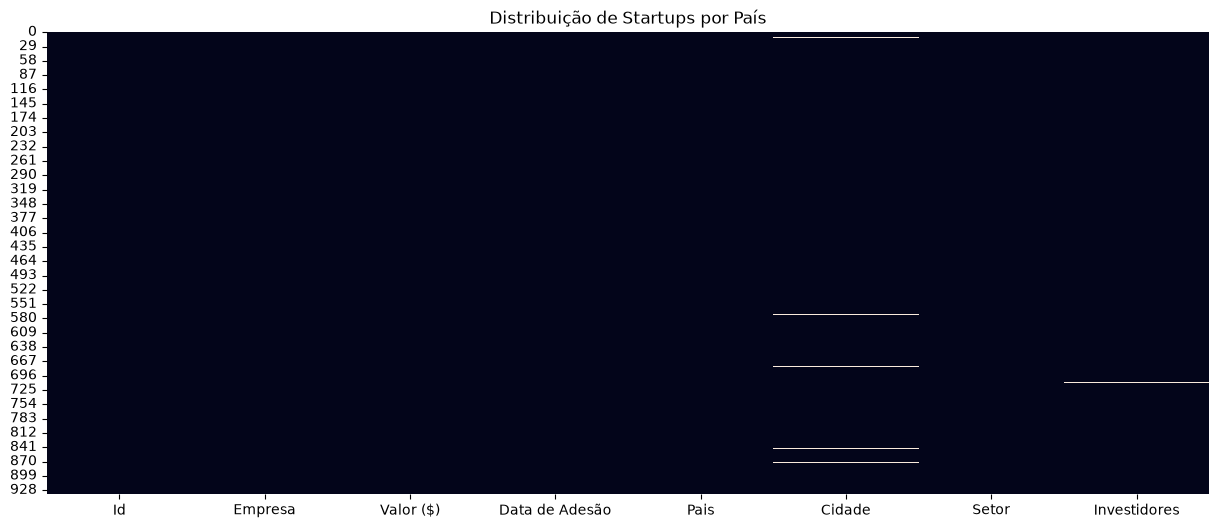

In [5]:
# Grafica
plt.figure(figsize=(15, 6))
plt.title('Distribuição de Startups por País')
sns.heatmap(base.isnull(), cbar=False);

In [6]:
#Campos Unicos
base.nunique()

     


Id                936
Empresa           935
Valor ($)         192
Data de Adesão    589
Pais               47
Cidade            239
Setor              17
Investidores      920
dtype: int64

In [7]:
#Valores Unicos - Rank
base['Pais'].value_counts()

Pais
United States           477
China                   169
India                    51
United Kingdom           37
Germany                  23
Israel                   21
France                   19
Brazil                   15
Canada                   15
South Korea              11
Singapore                11
Hong Kong                 7
Australia                 6
Japan                     6
Mexico                    5
Netherlands               5
Sweden                    4
Indonesia                 4
Switzerland               4
Spain                     4
Ireland                   3
United Arab Emirates      3
Norway                    3
Turkey                    2
Colombia                  2
Belgium                   2
Austria                   2
Finland                   2
Philippines               2
Denmark                   2
South Africa              2
Thailand                  2
Lithuania                 1
Estonia                   1
Vietnam                   1
Argentina      

In [8]:
base['Setor'].value_counts(normalize=True)

Setor
Fintech                                0.202991
Internet software & services           0.178419
E-commerce & direct-to-consumer        0.108974
Artificial intelligence                0.073718
Health                                 0.067308
Other                                  0.054487
Supply chain, logistics, & delivery    0.054487
Cybersecurity                          0.043803
Mobile & telecommunications            0.039530
Data management & analytics            0.038462
Hardware                               0.034188
Auto & transportation                  0.030983
Edtech                                 0.028846
Consumer & retail                      0.024573
Travel                                 0.013889
Artificial Intelligence                0.004274
Finttech                               0.001068
Name: proportion, dtype: float64

<BarContainer object of 17 artists>

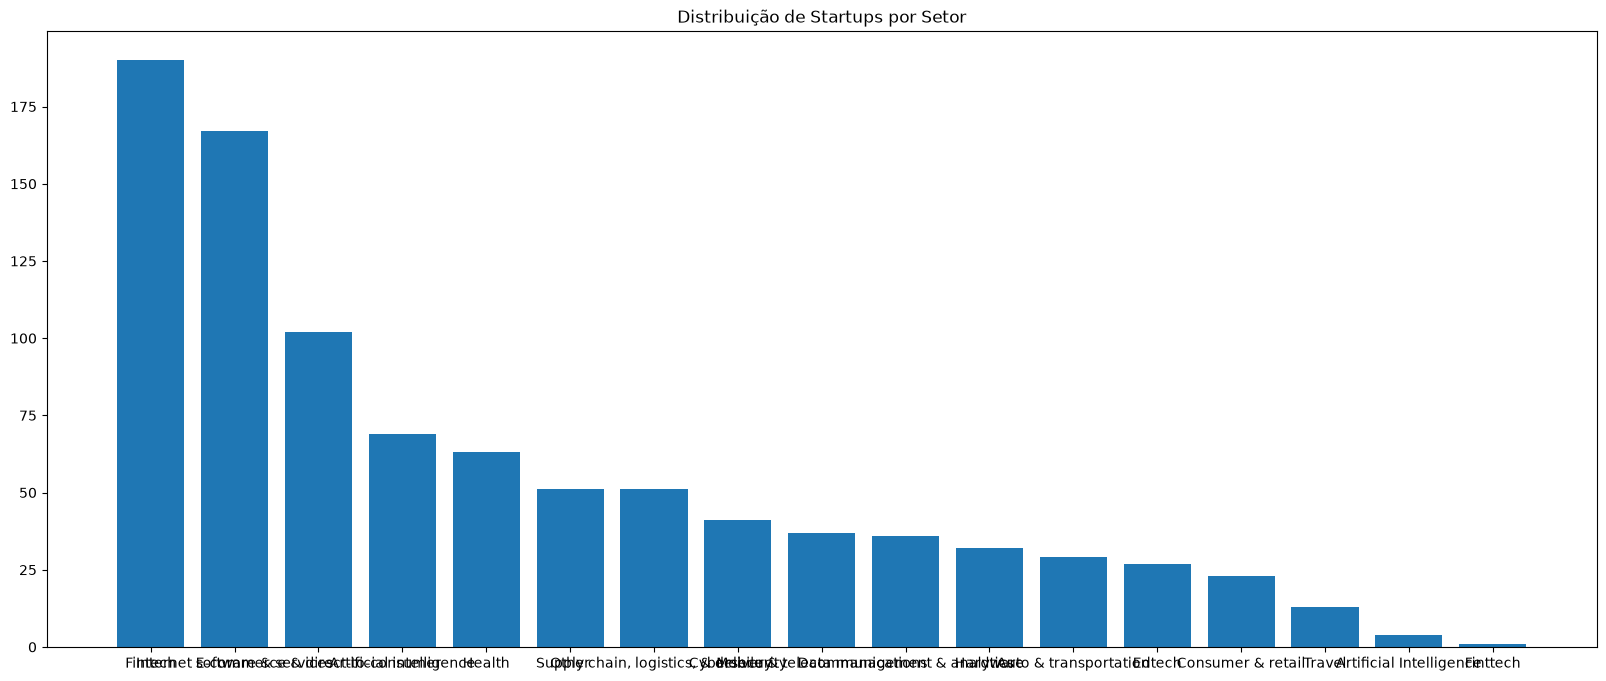

In [9]:
plt.figure(figsize=(20, 8))
plt.title('Distribuição de Startups por Setor')
plt.bar(base['Setor'].value_counts().index, base['Setor'].value_counts()    )

In [10]:
Analise = round(base['Pais'].value_counts(normalize=True) * 100, 1)

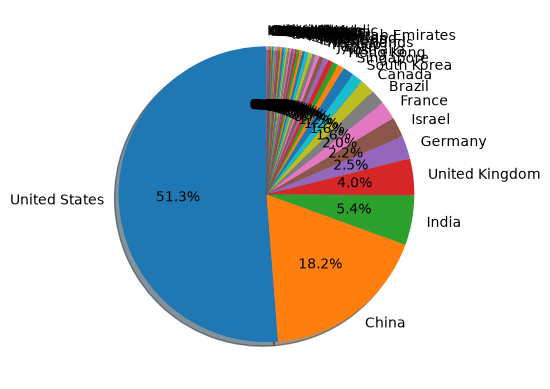

In [11]:
plt.pie(
    Analise, 
    labels=Analise.index, 
    shadow=True,
    startangle=90,
    autopct='%1.1f%%'
)

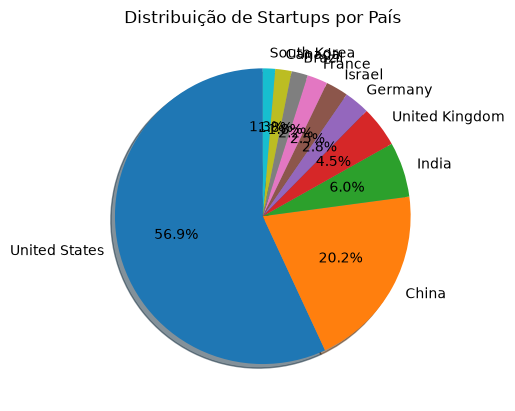

In [12]:
# Plot geral dos Países
plt.Figure(figsize=(20, 8))
plt.title('Distribuição de Startups por País')
plt.pie(
    Analise.head(10), 
    labels= Analise.index [0:10], 
    shadow=True,
    startangle=90,
    autopct='%1.1f%%'
);

In [13]:
Analise.head(10)

Pais
United States     51.0
China             18.1
India              5.4
United Kingdom     4.0
Germany            2.5
Israel             2.2
France             2.0
Brazil             1.6
Canada             1.6
South Korea        1.2
Name: proportion, dtype: float64

In [14]:
# Conversão para Data
base['Data de Adesão'] = pd.to_datetime(base['Data de Adesão']  )

base['Data de Adesão'].head()

0   2017-04-07
1   2012-12-01
2   2014-01-23
3   2011-12-12
4   2018-01-08
Name: Data de Adesão, dtype: datetime64[us]

In [15]:
# Extrair Ano e Mês
base['Mes'] = pd.DatetimeIndex ( base['Data de Adesão'] ).month

base['Ano'] = pd.DatetimeIndex ( base['Data de Adesão'] ).year

base.head()


,Id,Empresa,Valor ($),Data de Adesão,Pais,Cidade,Setor,Investidores,Mes,Ano
0,0,Bytedance,$140,2017-04-07,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",4,2017
1,1,SpaceX,$100.3,2012-12-01,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",12,2012
2,2,Stripe,$95,2014-01-23,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",1,2014
3,3,Klarna,$45.6,2011-12-12,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",12,2011
4,4,Canva,$40,2018-01-08,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat...",1,2018


In [23]:
#Tabela Analitica
base.groupby( by=['Pais','Setor',] ).sum(numeric_only=True)

Id  Mes    Ano
Pais           Setor                                                 
Argentina      Fintech                                298    8   2021
Australia      E-commerce & direct-to-consumer        935   12   2021
               Fintech                                117    3   2019
               Internet software & services          1849   20   8081
Austria        Edtech                                 443    6   2021
...                                                   ...  ...    ...
United States  Other                                11179  149  52508
               Supply chain, logistics, & delivery   9463  135  36354
               Travel                                 645   18   4037
United States, Health                                 899    9   2021
Vietnam        Internet software & services           253   10   2021

[183 rows x 3 columns]

In [17]:
# Transformando a coluna Valor
base['Valor ($)'] = base['Valor ($)'].apply(lambda Linha: Linha.replace('$', ''))

base.head()

,Id,Empresa,Valor ($),Data de Adesão,Pais,Cidade,Setor,Investidores,Mes,Ano
0,0,Bytedance,140,2017-04-07,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",4,2017
1,1,SpaceX,100.3,2012-12-01,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",12,2012
2,2,Stripe,95,2014-01-23,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",1,2014
3,3,Klarna,45.6,2011-12-12,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",12,2011
4,4,Canva,40,2018-01-08,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat...",1,2018


In [26]:
base.groupby(by=['Pais', 'Setor'])['Valor ($)'].sum().reset_index()

,Pais,Setor,Valor ($)
0,Argentina,Fintech,2.45
1,Australia,E-commerce & direct-to-consumer,1
2,Australia,Fintech,5.5
3,Australia,Internet software & services,401.61.51
4,Austria,Edtech,1.7
...,...,...,...
178,United States,Other,100.328.7106.14.243.73.32.42.32.32.221.81.631....
179,United States,"Supply chain, logistics, & delivery",393.22.82.82.752.3221.31.251.21.131.0511111
180,United States,Travel,7.251.3
181,"United States,",Health,1


In [37]:
Analise_Pais = base.groupby(by=['Pais', 'Setor'])['Valor ($)'].sum().reset_index()

Analise_Pais.head()


,Pais,Setor,Valor ($)
0,Argentina,Fintech,2.45
1,Australia,E-commerce & direct-to-consumer,1
2,Australia,Fintech,5.5
3,Australia,Internet software & services,401.61.51
4,Austria,Edtech,1.7


In [38]:
Analise_Pais.sort_values('Valor ($)', ascending=False)

,Pais,Setor,Valor ($)
168,United States,Cybersecurity,98.37.54.54.33.532.752.52.442.42.421.71.61.51....
172,United States,Fintech,952513.412.310108.387.47.1665.54.54.2443.93.75...
177,United States,Mobile & telecommunications,95.9943.321.51.41.291.11.0511
81,India,Travel,9.6
37,China,Other,9.283.241.551.31
...,...,...,...
150,Turkey,Mobile & telecommunications,1
107,Netherlands,E-commerce & direct-to-consumer,1
152,United Arab Emirates,"Supply chain, logistics, & delivery",1
125,South Africa,Mobile & telecommunications,1


In [39]:
Analise_Valor = Analise_Pais.sort_values('Valor ($)', ascending=False)

Analise_Valor.head()

,Pais,Setor,Valor ($)
168,United States,Cybersecurity,98.37.54.54.33.532.752.52.442.42.421.71.61.51....
172,United States,Fintech,952513.412.310108.387.47.1665.54.54.2443.93.75...
177,United States,Mobile & telecommunications,95.9943.321.51.41.291.11.0511
81,India,Travel,9.6
37,China,Other,9.283.241.551.31


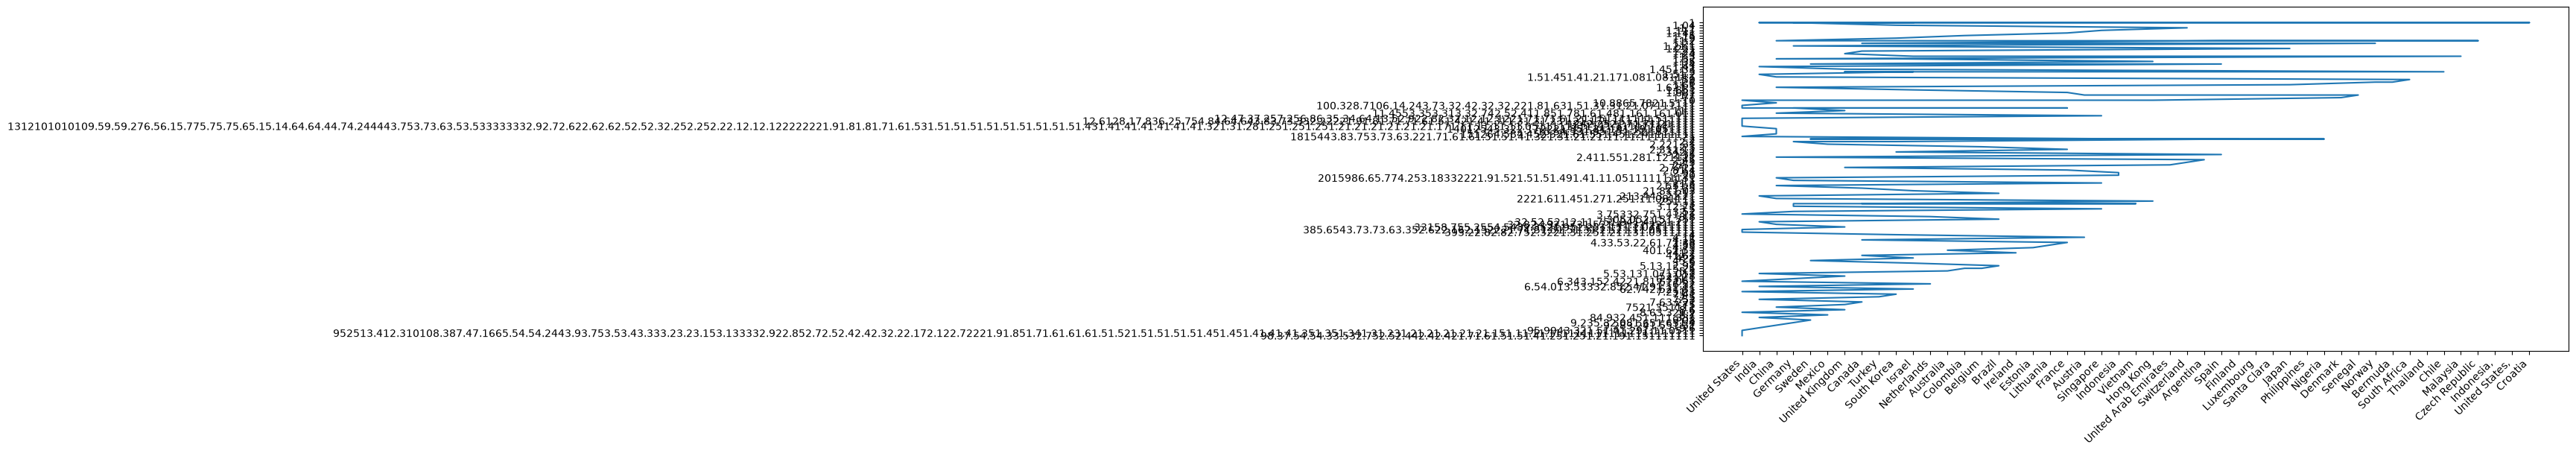

In [42]:
plt.figure(figsize=(15, 6) )
plt.plot (Analise_Valor['Pais'], Analise_Valor['Valor ($)'])
plt.xticks(rotation=45, ha='right');